# 10 · Tái thiết kế quy trình (BPR): AS-IS → TO-BE và KPI (Chương 4)

## 1. Mục tiêu và buổi học áp dụng

Trả lời **câu hỏi quản trị 4** (*nên tái thiết kế ra sao, đo hiệu quả bằng KPI gì?*). Áp dụng **Buổi 4 — BPR** (AS-IS/TO-BE, bài học Ford/Mazda, KPI) và các **BPR heuristics của Buổi 2** (triage, task automation, task composition, empower, control addition).

## 2. Đầu vào

Run `outputs/process/<run>` (bước D: `d_bpr/`), loader kiểm fingerprint. Ngưỡng kiểm chứng lấy từ cấu hình đã lưu trong manifest (khóa trước khi tính phán quyết).

In [1]:
# Mở run giai đoạn 2 đã kiểm fingerprint. Không cần biến môi trường: nếu không chỉ định, tự chọn run
# hoàn tất mới nhất khớp configs/process.yaml hiện tại (bộ chạy `jira-ad notebooks` đặt JIRA_AD_PROCESS_RUN_DIR).
import pandas as pd
from IPython.display import Markdown, display

from jira_ad import process_plots as pp
from jira_ad.process_analysis import fmt, open_process_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 100
run = open_process_run()
print(run.header())

run: outputs/process/20261026T025412Z-399b0a40
chọn run: biến môi trường JIRA_AD_PROCESS_RUN_DIR
config: configs/process.yaml
config_hash: 399b0a40534a3d08466aaaf32175a68cb6d59cf4d90af65301ebb04c5e572a22
code.sha256: ed83115da72a96af6ecac17610d370d96a617635e4abc0c807ee7459ba84e9b6
tạo lúc (UTC): 2026-10-26T02:54:12.298067+00:00
số artifact đã kiểm sha256: 93


In [2]:
display(pd.Series(run.manifest["config"]["bpr"], name="ngưỡng khóa trước").to_frame())

,ngưỡng khóa trước
early_triage_min_share,0.200
early_triage_min_median_days,5.000
auto_transition_min_share,0.300
merge_max_days,1.000
merge_min_share,0.500
po_state,To Do
duplicate_pattern,link to duplicates
duplicate_min_cases,5
duplicate_min_median_days,5.000
investigating_min_width_pp,10.000


## 3. Dữ liệu và giả định

- **Mỗi ứng viên cải tiến được kiểm chứng trên dữ liệu** bằng một câu hỏi đo được và ngưỡng **khóa trước** (1 tuần làm việc = 5 ngày; "đáng kể" = 20%; "đa số" = 50%; bootstrap 95% loại trừ 0). Phán quyết: ủng hộ / không ủng hộ / không đủ dữ liệu.
- **What-if là tính lại trên chính log**, không phải mô phỏng, không phải kết quả của thay đổi đã triển khai: mọi số TO-BE là **mục tiêu / kịch bản ước tính**, thường là **cận trên** của lợi ích, kèm giả định ở từng dòng.
- **Mô hình TO-BE được thiết kế sau khi có phán quyết** và chỉ gồm ứng viên được ủng hộ (Ruling 95).
- Mức vai trò, không đánh giá cá nhân; PT/WT vẫn là xấp xỉ như Chương 2.

**Bài học Ford/Mazda (Buổi 4) áp vào đây.** Ford không làm nhanh hơn việc đối chiếu hóa đơn mà *bỏ hẳn* bước đó nhờ thay đổi cách thông tin chảy; Mazda cho thấy khoảng cách lớn giữa hai cách tổ chức cùng một công việc. Tương tự: (1) thay vì nhắc người dùng cập nhật trạng thái, để commit/MR tự chuyển `In Progress` (bỏ thao tác thủ công); (2) so luồng "bỏ điều tra" với luồng có điều tra trên chính dữ liệu của team để thấy khoảng cách giữa hai cách xử lý (bảng 4.1), thay vì cải thiện từng bước nhỏ trong luồng cũ.

## 4. Kết quả

### 4.1 Kiểm chứng các ứng viên (đúng/sai theo ngưỡng khóa trước)

In [3]:
checks = run.csv("d_bpr/checks.csv")
display(checks[["candidate", "question", "metric", "value", "threshold", "verdict", "evidence"]])

,candidate,question,metric,value,threshold,verdict,evidence
0,early_triage,Ca Rejected có tốn phần đáng kể thời gian trước khi bị loại không?,tỉ trọng ngày-issue làm việc của ca Rejected,0.368,>= 0.2 và trung vị >= 5.0 ngày,ủng hộ,"78 ca Rejected; trung vị 13,4 ngày làm việc tới khi bị loại; 47/78 ca bị loại ngay sau INVESTIGA..."
1,auto_transition,Commit/MR có xuất hiện trước khi chuyển In Progress không?,tỉ lệ ca liên kết commit/MR trước khi vào In Progress,0.672,>= 0.3,ủng hộ,"39/58 ca; trễ trung vị 1,7 ngày lịch giữa liên kết đầu tiên và lúc chuyển In Progress; liên kết ..."
2,merge_investigated,INVESTIGATED → To Do có chỉ là bước đi xuyên qua không?,tỉ lệ lần INVESTIGATED → To Do trong <= 1.0 ngày làm việc,0.694,>= 0.5,ủng hộ,"43/62 lần chuyển; trung vị 0,0 ngày"
3,reduce_po_dependency,Chờ ở To Do có gắn với PO (vai trò chuyển ra) không?,trung vị dwell (PO chuyển ra) − (vai trò khác),0.000,CI 95% > 0,không ủng hộ,"46 lượt PO (trung vị 0,0 ngày) so với 25 lượt vai trò khác (trung vị 0,0 ngày); CI 95% [0,0; 0,9]"
4,early_duplicate_detection,Ca bị loại vì trùng có bị phát hiện muộn không?,trung vị ngày làm việc tới khi Rejected (ca trùng),3.180,>= 5.0 ngày,không ủng hộ,"7 ca Rejected có liên kết 'link to duplicates'; trung vị 3,2 ngày làm việc tới khi bị loại"
5,add_investigating_state,Công sức điều tra có bị Jira che khuất (PT phụ thuộc cách xếp To Investigate)?,độ rộng khoảng PT (điểm %),42.512,> 10.0 và do cách xếp To Investigate,ủng hộ,"PT chính 16,7%, nếu To Investigate là làm 57,0%"
6,fast_track,Ca DONE bỏ pha điều tra có chậm hơn hoặc nhiều làm lại hơn không?,trung vị CT ngày làm việc (bỏ điều tra − có điều tra),-24.743,<= 0 và FPY giảm <= 0.1,ủng hộ,"32 ca bỏ điều tra: CT 11,2 ngày, FPY 0,75; 51 ca có điều tra: CT 35,9 ngày, FPY 0,76"


### 4.2 Vấn đề → bằng chứng → thủ pháp BPR

In [4]:
display(run.csv("d_bpr/problems.csv")[["candidate", "problem", "evidence", "heuristic", "verdict", "in_tobe"]])

,candidate,problem,evidence,heuristic,verdict,in_tobe
0,early_triage,Ca bị từ chối vẫn nằm lâu trong quy trình trước khi bị loại,"78 ca Rejected; trung vị 13,4 ngày làm việc tới khi bị loại; 47/78 ca bị loại ngay sau INVESTIGA...",Triage / knock-out sớm: quyết định loại ngay ở Inbox,ủng hộ,True
1,auto_transition,Trạng thái Jira cập nhật muộn so với công việc thật (commit/MR có trước In Progress),"39/58 ca; trễ trung vị 1,7 ngày lịch giữa liên kết đầu tiên và lúc chuyển In Progress; liên kết ...",Task automation: tự chuyển In Progress khi có commit/MR đầu tiên,ủng hộ,True
2,merge_investigated,INVESTIGATED thường chỉ là bước đi xuyên qua trước To Do,"43/62 lần chuyển; trung vị 0,0 ngày",Task composition: gộp INVESTIGATED vào To Do,ủng hộ,True
3,reduce_po_dependency,PO là vai trò cổng của phần lớn trạng thái chờ,"46 lượt PO (trung vị 0,0 ngày) so với 25 lượt vai trò khác (trung vị 0,0 ngày); CI 95% [0,0; 0,9]",Empower / phân quyền: giảm số bước phải chờ PO,không ủng hộ,False
4,early_duplicate_detection,Bug trùng có thể bị phát hiện muộn,"7 ca Rejected có liên kết 'link to duplicates'; trung vị 3,2 ngày làm việc tới khi bị loại",Knock-out sớm: kiểm tra trùng ngay khi tạo,không ủng hộ,False
5,add_investigating_state,Công sức điều tra không hiện trong Jira (To Investigate vừa là hàng đợi vừa là việc),"PT chính 16,7%, nếu To Investigate là làm 57,0%",Control addition: thêm trạng thái Investigating để đo được việc điều tra,ủng hộ,True
6,fast_track,Mọi bug đều phải qua điều tra dù một phần được sửa thẳng,"32 ca bỏ điều tra: CT 11,2 ngày, FPY 0,75; 51 ca có điều tra: CT 35,9 ngày, FPY 0,76",Triage: phân luồng bug rõ ràng sang To Do (luồng nhanh),ủng hộ,True


### 4.3 Kiểm chứng: chờ ở To Do có gắn với PO không?

Phán quyết dùng **trung vị** (khóa trước); bảng dưới là **mô tả bổ sung** về phần đuôi (ngày vượt định mức), không thay phán quyết.

,value,threshold,verdict,evidence
3,0.000,CI 95% > 0,không ủng hộ,"46 lượt PO (trung vị 0,0 ngày) so với 25 lượt vai trò khác (trung vị 0,0 ngày); CI 95% [0,0; 0,9]"


,role,n_visits,n_late,excess_days,is_human,share_of_state_excess
0,PO,46,12,701.125,True,0.605
1,unknown,35,12,427.947,False,0.369
2,Eng,23,2,29.025,True,0.025
3,SQA,1,1,1.249,True,0.001
4,RTE,1,0,0.000,True,0.000


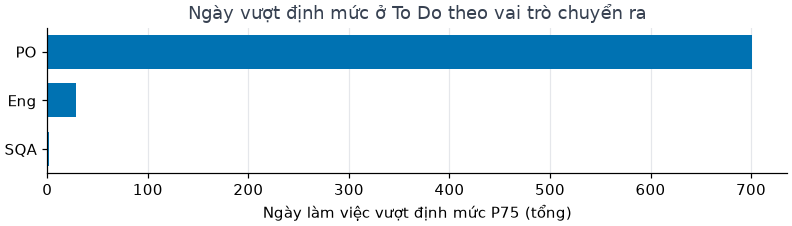

In [5]:
display(checks[checks.candidate == "reduce_po_dependency"][["value", "threshold", "verdict", "evidence"]])
todo = run.csv("d_bpr/todo_excess_by_role.csv")
display(todo)
_ = run.show(pp.plot_excess_days(todo[todo.is_human], key="role",
                                 title="Ngày vượt định mức ở To Do theo vai trò chuyển ra"))

### 4.4 KPI: AS-IS (đo) và TO-BE (mục tiêu / kịch bản ước tính)

,kpi,unit,asis,tobe,delta,delta_pct,tobe_label,scenario,assumption
0,ct_work_median_days,ngày làm việc,17.032,15.212,-1.820,-0.107,mục tiêu / kịch bản ước tính,từ chối khi kết thúc điều tra + giới hạn chờ To Do,Ca Rejected đã qua điều tra được quyết ngay khi rời To Investigate (bỏ chờ ở INVESTIGATED và sau...
1,ct_work_p90_days,ngày làm việc,74.307,57.876,-16.431,-0.221,mục tiêu / kịch bản ước tính,từ chối khi kết thúc điều tra + giới hạn chờ To Do,Ca Rejected đã qua điều tra được quyết ngay khi rời To Investigate (bỏ chờ ở INVESTIGATED và sau...
2,ct_work_median_days_upper,ngày làm việc,17.032,5.873,-11.158,-0.655,mục tiêu / kịch bản ước tính,early_triage cận trên + giới hạn chờ To Do,CẬN TRÊN: mọi ca Rejected được quyết ở lần đổi trạng thái đầu (kể cả ca cần điều tra); chờ ở To ...
3,rejected_issue_days_work,ngày-issue làm việc,1928.560,1394.208,-534.351,-0.277,mục tiêu / kịch bản ước tính,từ chối khi kết thúc điều tra,Ca Rejected đã qua điều tra được quyết ngay khi rời To Investigate; ca không qua điều tra giữ ng...
4,rejected_issue_days_work_upper,ngày-issue làm việc,1928.560,264.233,-1664.327,-0.863,mục tiêu / kịch bản ước tính,early_triage cận trên,CẬN TRÊN: thông tin để từ chối đã có từ lần đổi trạng thái đầu cho mọi ca
5,pt_share_main,tỉ lệ,0.167,0.169,0.001,0.007,mục tiêu / kịch bản ước tính,auto_transition,"Chỉ phần To Do sau liên kết commit/MR đầu tiên được tính là làm (cải thiện ĐO LƯỜNG, CT không đổ..."
6,status_changes_per_case,lần/ca,4.435,5.429,0.994,0.224,mục tiêu / kịch bản ước tính,đường TO-BE,"Đường AS-IS của mỗi ca chuyển sang đường TO-BE: bỏ INVESTIGATED, thêm Investigating, đi qua Inbo..."
7,conformance_share_fit,tỉ lệ ca khớp,0.652,0.807,0.155,0.238,mục tiêu / kịch bản ước tính,fast_track,"Mô hình chính thức cho phép luồng nhanh CREATE → To Do; hành vi thực tế không đổi, chỉ đổi chuẩn..."


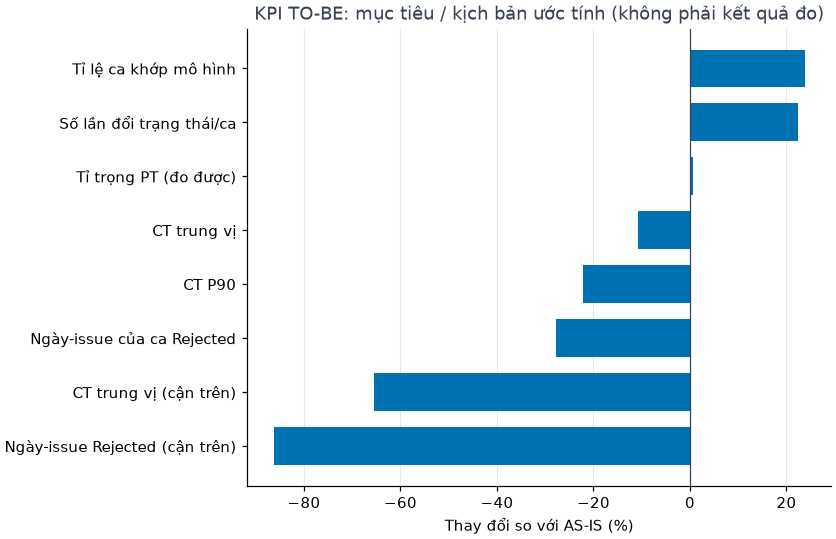

In [6]:
kpi = run.csv("d_bpr/kpi_asis_tobe.csv")
display(kpi[["kpi", "unit", "asis", "tobe", "delta", "delta_pct", "tobe_label", "scenario", "assumption"]])
_ = run.show(pp.plot_kpi_delta(kpi))

### 4.5 Mô hình TO-BE

File BPMN 2.0: `d_bpr/tobe_model.bpmn` (cung tự động được đặt tên trên sequence flow). So với mô hình chuẩn AS-IS ở notebook 09.

,cung TO-BE
0,CREATE -> Inbox
1,Inbox -> Rejected
2,Inbox -> To Do
3,Inbox -> To Investigate
4,To Investigate -> Investigating
5,Investigating -> To Do
6,Investigating -> Rejected
7,To Do -> In Progress
8,To Do -> Rejected
9,In Progress -> In Test


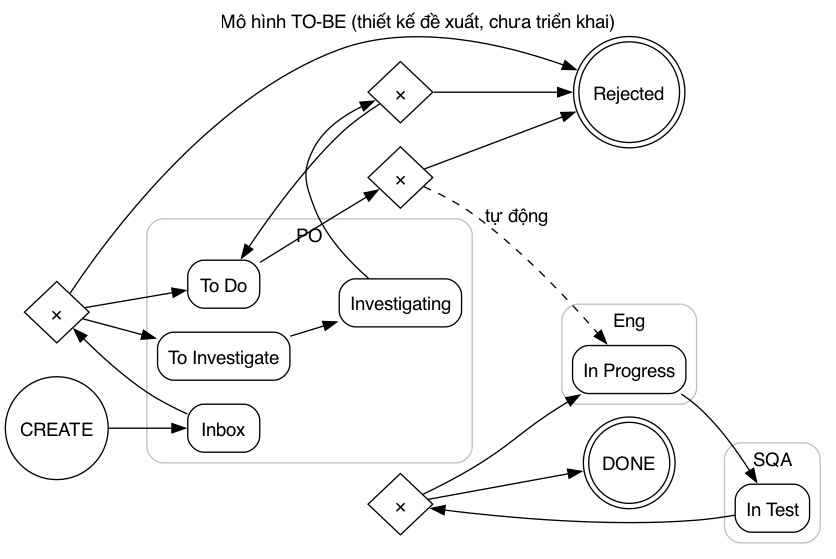

In [7]:
from IPython.display import Image
display(pd.DataFrame({"cung TO-BE": run.manifest["config"]["tobe_model"]["arcs"]}))
display(Image(filename=str(run.path("d_bpr/tobe_model.png"))))

### 4.6 Kế hoạch pilot

In [8]:
display(run.csv("d_bpr/pilot.csv"))

,phase,weeks,action,kpi,baseline_asis,target_tobe,unit,tobe_label,note
0,chuan_bi,1–2,"Cấu hình Jira: thêm Investigating, bỏ INVESTIGATED, tự chuyển In Progress khi có commit/MR; họp ...",status_changes_per_case,4.435,5.429,lần/ca,mục tiêu / kịch bản ước tính,NaN
1,chuan_bi,1–2,"Cấu hình Jira: thêm Investigating, bỏ INVESTIGATED, tự chuyển In Progress khi có commit/MR; họp ...",pt_share_main,0.167,0.169,tỉ lệ,mục tiêu / kịch bản ước tính,NaN
2,chay_thu,3–8,Chạy quy trình TO-BE với một team; ghi nhận ca đi luồng nhanh và ca bị loại sớm,ct_work_median_days,17.032,15.212,ngày làm việc,mục tiêu / kịch bản ước tính,NaN
3,chay_thu,3–8,Chạy quy trình TO-BE với một team; ghi nhận ca đi luồng nhanh và ca bị loại sớm,rejected_issue_days_work,1928.560,1394.208,ngày-issue làm việc,mục tiêu / kịch bản ước tính,NaN
4,chay_thu,3–8,Chạy quy trình TO-BE với một team; ghi nhận ca đi luồng nhanh và ca bị loại sớm,conformance_share_fit,0.652,0.807,tỉ lệ ca khớp,mục tiêu / kịch bản ước tính,NaN
5,danh_gia,9–10,So KPI pilot với mốc AS-IS bằng cùng định nghĩa; tiếp tục nếu KPI chính đi đúng hướng mục tiêu v...,ct_work_median_days,17.032,15.212,ngày làm việc,mục tiêu / kịch bản ước tính,NaN
6,danh_gia,9–10,So KPI pilot với mốc AS-IS bằng cùng định nghĩa; tiếp tục nếu KPI chính đi đúng hướng mục tiêu v...,ct_work_p90_days,74.307,57.876,ngày làm việc,mục tiêu / kịch bản ước tính,NaN
7,danh_gia,9–10,So KPI pilot với mốc AS-IS bằng cùng định nghĩa; tiếp tục nếu KPI chính đi đúng hướng mục tiêu v...,rejected_issue_days_work,1928.560,1394.208,ngày-issue làm việc,mục tiêu / kịch bản ước tính,NaN
8,danh_gia,9–10,So KPI pilot với mốc AS-IS bằng cùng định nghĩa; tiếp tục nếu KPI chính đi đúng hướng mục tiêu v...,conformance_share_fit,0.652,0.807,tỉ lệ ca khớp,mục tiêu / kịch bản ước tính,NaN


## 5. Quá trình nghiên cứu

- **Ngưỡng khóa trước, TO-BE thiết kế sau**: ngưỡng của bảy phép kiểm chứng được ghi vào YAML trước khi tính bất kỳ phán quyết nào; mô hình TO-BE và kế hoạch pilot được thiết kế sau, chỉ từ ứng viên được ủng hộ (Ruling 94, 95).
- **Ghi chú của người dùng** về PO đã được kiểm chứng thay vì mặc nhiên đề xuất: theo trung vị thì **không** được ủng hộ; phần đuôi được trình bày như mô tả (Ruling 96).
- **Auto-transition** được ủng hộ theo tỉ lệ ca, nhưng what-if cho thấy lợi ích đo lường nhỏ vì độ trễ giữa commit đầu tiên và lúc chuyển trạng thái ngắn — cả hai được báo cạnh nhau.
- **Lỗi do chính agent gây ra khi ngắt dòng cho ruff**: một f-string đứng trước biểu thức trong ngoặc bị Python hiểu thành lời gọi hàm ⇒ lần chạy thật thất bại (`TypeError`), trong khi test ghép nối không chạm tới nhánh đó. Đã sửa, chạy lại loạt đột biến bị ảnh hưởng, thêm test hồi quy ghép nối có cả hai nhóm (Ruling 97).
- **Một lần làm sai thứ tự TDD** (test và code của `problem_table`/`pilot_plan` viết cùng lúc) được bù bằng đột biến — tất cả bị bắt (Ruling 97).
- **Kiểm chéo độc lập** ngày-issue của ca Rejected AS-IS và TO-BE bằng pandas thô: khớp pipeline.
- **Sau rà soát độc lập (Task 25)**: (i) kịch bản chính đổi sang "từ chối ngay khi kết thúc điều tra" — nhất quán với TO-BE vẫn có Investigating → Rejected — còn "quyết ở lần đổi đầu" chỉ là cận trên (dòng riêng); (ii) số lần đổi trạng thái tính theo đường TO-BE thật (tăng, vì thêm bước đo lường); (iii) bằng chứng tự chuyển trạng thái nêu trạng thái chứa liên kết đầu; (iv) phần đuôi PO ở To Do tách theo trạng thái đích — chủ yếu là dọn backlog (Ruling 107–109).

## 6. Nhận xét sinh từ số liệu

In [9]:
from jira_ad.process_analysis import remarks_bpr
display(Markdown("\n".join(f"- {line}" for line in remarks_bpr(run))))

- early_triage: ủng hộ — 78 ca Rejected; trung vị 13,4 ngày làm việc tới khi bị loại; 47/78 ca bị loại ngay sau INVESTIGATED (phép kiểm đo quy mô vấn đề, không đo được bao nhiêu ca có thể quyết sớm hơn).
- auto_transition: ủng hộ — 39/58 ca; trễ trung vị 1,7 ngày lịch giữa liên kết đầu tiên và lúc chuyển In Progress; liên kết đầu rơi vào: To Investigate 22, To Do 12, __CREATED__ 5 (cung tự động To Do → In Progress chỉ áp dụng cho 12 ca).
- merge_investigated: ủng hộ — 43/62 lần chuyển; trung vị 0,0 ngày.
- reduce_po_dependency: không ủng hộ — 46 lượt PO (trung vị 0,0 ngày) so với 25 lượt vai trò khác (trung vị 0,0 ngày); CI 95% [0,0; 0,9].
- early_duplicate_detection: không ủng hộ — 7 ca Rejected có liên kết 'link to duplicates'; trung vị 3,2 ngày làm việc tới khi bị loại.
- add_investigating_state: ủng hộ — PT chính 16,7%, nếu To Investigate là làm 57,0%.
- fast_track: ủng hộ — 32 ca bỏ điều tra: CT 11,2 ngày, FPY 0,75; 51 ca có điều tra: CT 35,9 ngày, FPY 0,76.
- ct_work_median_days: AS-IS (đo) 17,0 → TO-BE 15,2 (mục tiêu / kịch bản ước tính; kịch bản từ chối khi kết thúc điều tra + giới hạn chờ To Do).
- ct_work_p90_days: AS-IS (đo) 74,3 → TO-BE 57,9 (mục tiêu / kịch bản ước tính; kịch bản từ chối khi kết thúc điều tra + giới hạn chờ To Do).
- ct_work_median_days_upper: AS-IS (đo) 17,0 → TO-BE 5,9 (mục tiêu / kịch bản ước tính; kịch bản early_triage cận trên + giới hạn chờ To Do).
- rejected_issue_days_work: AS-IS (đo) 1.928,6 → TO-BE 1.394,2 (mục tiêu / kịch bản ước tính; kịch bản từ chối khi kết thúc điều tra).
- rejected_issue_days_work_upper: AS-IS (đo) 1.928,6 → TO-BE 264,2 (mục tiêu / kịch bản ước tính; kịch bản early_triage cận trên).
- pt_share_main: AS-IS (đo) 16,7% → TO-BE 16,9% (mục tiêu / kịch bản ước tính; kịch bản auto_transition).
- status_changes_per_case: AS-IS (đo) 4,4 → TO-BE 5,4 (mục tiêu / kịch bản ước tính; kịch bản đường TO-BE).
- conformance_share_fit: AS-IS (đo) 65,2% → TO-BE 80,7% (mục tiêu / kịch bản ước tính; kịch bản fast_track).
- Mô tả bổ sung (không phải phán quyết): 60,5% số ngày vượt định mức ở To Do rơi vào lượt do PO chuyển ra dù phép kiểm theo trung vị không ủng hộ ⇒ dồn đọng nằm ở đuôi phân bố.

## 7. Giả định, giới hạn, việc tiếp theo

- Mọi số TO-BE là mục tiêu / kịch bản ước tính trên log hiện có, không phải lợi ích đã chứng minh; early triage là cận trên (giả định thông tin để từ chối đã có từ đầu).
- So sánh luồng nhanh với luồng có điều tra là quan sát, **không nhân quả**: bug được sửa thẳng có thể vốn đơn giản hơn.
- Việc tiếp theo: pilot theo bảng 4.6, đo lại bằng chính lệnh `jira-ad process` trên dữ liệu pilot với cùng định nghĩa; Chương 6 dùng các cờ và độ lệch để xếp hạng ca nên xem trước.